In [96]:
import numpy as np 
import scipy as sp
from scipy import special 
from scipy import integrate
import matplotlib.pyplot as plt
from scripts.compiled import field 

In [69]:
def br_scalar(r, a, lam, qmax=10000):
    kappa = 1.0 / (2.0 * lam)

    def f(q):
        return -q / (q + kappa) * special.j0(q*a) * special.j1(q*r)

    # Choose interval width based on the Bessel oscillation scale.
    scale = max(a, r, 1e-12)
    dq = np.pi / scale
    edges = np.arange(0, qmax, dq)
    edges = np.append(edges, qmax)

    total = 0.0

    for lo, hi in zip(edges[:-1], edges[1:]):
        val, err = integrate.quad(
            f, lo, hi, epsabs=1e-9, epsrel=1e-9, limit=100
        )
        total += val

    return total

[]

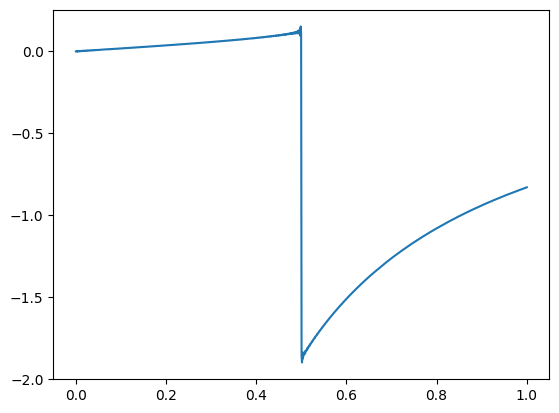

In [71]:
r = np.linspace(0, 1, 1000)
plt.plot(r, np.vectorize(br_scalar)(r, 0.5, 2))
plt.plot()

In [94]:
theta = lambda r: (special.k1(r) - 1 / r)

/var/folders/dh/t0mhz41x5m190dc1421tsc5r0000gn/T/ipykernel_27334/3441664038.py:1: RuntimeWarning: divide by zero encountered in divide
  theta = lambda r: (special.k1(r) - 1 / r)
/var/folders/dh/t0mhz41x5m190dc1421tsc5r0000gn/T/ipykernel_27334/3441664038.py:1: RuntimeWarning: invalid value encountered in subtract
  theta = lambda r: (special.k1(r) - 1 / r)


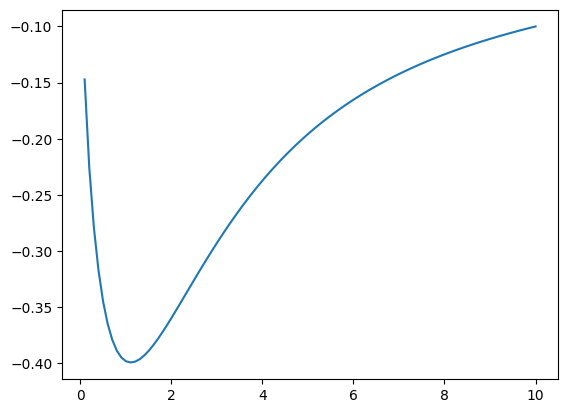

In [95]:
r = np.linspace(0, 10, 100)
plt.plot(r, theta(r))

Приближение малого $\gamma \ll 1$:
$$
\mathbf m \approx \mathbf e_z + \mathbf e_r \gamma \theta_b(r),\quad \theta_b(r) \approx K_1(r) - 1 / r
$$
$$
\mathcal{F}_\mathrm{VE} = \int E_{\mathbf a}^z \cfrac{\partial_r (r\,m_r)}{r} = 2\pi \int_0^\infty \bar E_a^z(r)\gamma\left[K_1(r) - \frac{r}{2}(K_0(r) - K_2(r))\right]\quad \propto\ \gamma \cdot \beta
$$

$$
\mathcal{F}_\mathrm{SkE} = \int E_{\mathbf a}^z [m_z (\nabla \mathbf m) - (\mathbf m\nabla) m_z]
$$

In [102]:
F_VE = np.vectorize(
    lambda a: 2 * np.pi * integrate.quad(lambda r: field(r, 1, a) * (special.k1(r) - r/2 * (special.k0(r) + special.kn(2, r))), 0, 30)[0]
)

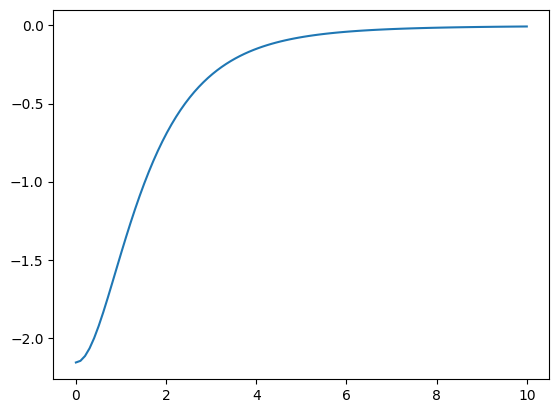

In [ ]:
a = np.linspace(0, 10, 100)

plt.plot(a,F_VE(a))

В симметричном приближении (соосный анзац):
$$
\bar {\mathbf m}: \theta(r) \approx \theta_{R\delta}(r) + \gamma \theta_{\mathbf {\bar b}}(r) \cos \theta_{R\delta}(r)
$$
В несимметричной конфигурации:
$$
\mathbf m = \underbrace{\mathbf m_{R\delta} + \gamma [\mathbf m_{R\delta} \times \bm \mu_{\mathbf {\bar b}, \mathbf a} \times \mathbf m_{R\delta}]}_{\bar {\mathbf m}} + \underbrace{\gamma [\bar {\mathbf m} \times (\bm \mu_{\mathbf b, \mathbf a} -\bm \mu_{\mathbf {\bar b}, \mathbf a}) \times \bar {\mathbf m}]}_{ \delta \mathbf m}
$$
$$
\mathbf m = \bar {\mathbf m} + \underbrace{\gamma [\bar {\mathbf m} \times (\bm \mu_{\mathbf b, \mathbf a} -\bm \mu_{\mathbf {\bar b}, \mathbf a}) \times \bar {\mathbf m}]}_{ \delta \mathbf m}
$$

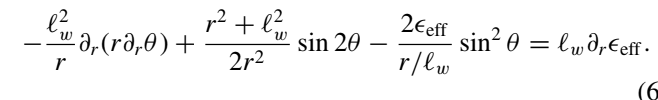